# Assignment 5: scikit-learn

- **you will learn:** Build preprocessing pipelines, combine them with regression models, and evaluate their performance
- **task:** See Section 5.8
- **deadline:** 29.11.2026
- [scikit-learn documentation](https://scikit-learn.org/)
- **Reminder:** Sync your GitHub repository with the main course repository, update your project in PyCharm, and, after completing the assignment, commit and push your changes to GitHub.

---


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from IPython.display import display

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

NumPy: 2.5.5
pandas: 3.1.1
scikit-learn: 1.9.1


## 5.1 Introduction to scikit-learn

In this session, we will use **scikit-learn** not just as a collection of machine learning models, but primarily as a **framework** for:

- preparing and preprocessing data;
- building end-to-end pipelines;
- evaluating models consistently and reproducibly.

### What Is scikit-learn?

Scikit-learn is built around **estimators**: objects that follow a simple, consistent interface (API). Common methods include:

- `fit(X, y)` — learn from data;
- `predict(X)` — make predictions;
- `transform(X)` — transform data, typically during preprocessing.

Objects that learn from data in scikit-learn are called **estimators**. Here is a minimal example of fitting a regression model (the variables `X_train`, `y_train`, and `X_test` will be defined later):

```python
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)
preds = model.predict(X_test)
```

### Estimators vs. Transformers

- **Estimator:** An object that implements `fit()` and can learn from data. Examples include `LinearRegression`, `RandomForestRegressor`, and `StandardScaler`.
- **Transformer:** An estimator that also implements `transform()` and can modify data (e.g., by scaling, encoding, or imputing values). Examples include `StandardScaler`, `OneHotEncoder`, and `SimpleImputer`.
- **Predictive model:** Typically implements `fit()` and `predict()`; a transformer typically implements `fit()` and `transform()` (and often `fit_transform()`).

A `Pipeline` can combine transformers and a predictive model into a single workflow.


### A Typical scikit-learn Workflow:

1. Load the dataset.
2. Inspect its structure.
3. Split the data into training and test sets.
4. Define preprocessing steps.
5. Combine preprocessing and a model in a `Pipeline`.
6. Train the pipeline using `fit()`.
7. Evaluate its performance on unseen test data.

---


## 5.2 Load and Inspect the Dataset

We will predict the **median house value in California census block groups**. The target is expressed in units of **\\$100,000**: for example, a target value of `2.5` corresponds to approximately $250,000.

All features in the original dataset are numerical. For teaching purposes, we will:

- derive a categorical feature, `HouseAge_cat`, from `HouseAge` to demonstrate encoding;
- deliberately introduce missing values into `Population` to demonstrate imputation.

The original dataset does not contain missing values.


In [2]:
housing = pd.read_csv("california_housing.csv")

X = housing.drop(columns="MedHouseVal")
y = housing["MedHouseVal"]

# A teaching example: derive a categorical variable from HouseAge.
X["HouseAge_cat"] = pd.cut(
    X["HouseAge"], bins=[0, 20, 50, np.inf],
    labels=["new", "middle", "old"]
)

# A teaching example: introduce 5% missing values in one numeric column.
rng = np.random.default_rng(67)
missing_rows = rng.choice(X.index, size=int(0.05 * len(X)), replace=False)
X.loc[missing_rows, "Population"] = np.nan

print("Features:", X.shape, "Target:", y.shape)
display(X.head())
display(pd.DataFrame({"dtype": X.dtypes.astype(str), "missing": X.isna().sum()}))

Features: (20640, 9) Target: (20640,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,HouseAge_cat
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,middle
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,middle
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,old
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,old
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,old


,dtype,missing
MedInc,float64,0
HouseAge,float64,0
AveRooms,float64,0
AveBedrms,float64,0
Population,float64,1032
AveOccup,float64,0
Latitude,float64,0
Longitude,float64,0
HouseAge_cat,category,0


## 5.3 Train–Test Split

In machine learning, we typically divide a dataset into:

- **Training set:** Used to fit the model and learn preprocessing parameters.
- **Test set:** Kept separate and used to assess the trained model on unseen data.

This distinction helps us evaluate how well a model **generalizes**. A model that performs very well on the training data may still **overfit** and perform poorly on new observations.

We will create the split using `sklearn.model_selection.train_test_split`.


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=67,
    shuffle=True,
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

# Fit preprocessors on the training data only.
print("Missing Population values in train:", X_train["Population"].isna().sum())


Training rows: 16512
Test rows: 4128
Missing Population values in train: 811


### Key Points

- Split the data **before fitting preprocessing steps or models**.
- `test_size=0.2` reserves 20% of the observations for testing; the appropriate fraction depends on the dataset.
- `random_state` makes the random split reproducible.
- `shuffle=True` (the default) shuffles observations before splitting, but does **not** guarantee representative samples. Time-ordered data usually require a different splitting strategy.
- Compare the target distributions in the training and test sets as a basic diagnostic:


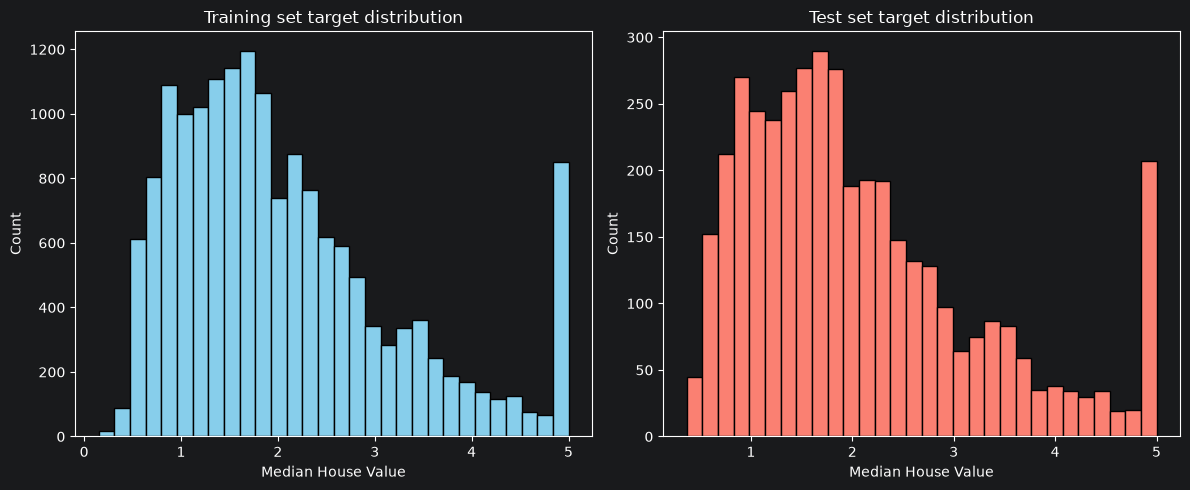

In [4]:
# Compare target distributions in the training and test sets.
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(y_train, bins=30, color="skyblue", edgecolor="black")
plt.title("Training set target distribution")
plt.xlabel("Median House Value")
plt.ylabel("Count")

plt.subplot(1, 2, 2)
plt.hist(y_test, bins=30, color="salmon", edgecolor="black")
plt.title("Test set target distribution")
plt.xlabel("Median House Value")
plt.ylabel("Count")

plt.tight_layout()
plt.show()


## 5.4 Our First Estimators: A Baseline and a Linear Model

A **baseline** provides a reference point for evaluating a model. `DummyRegressor(strategy="mean")` always predicts the mean target value in the training set.

We will compare this baseline with a simple linear regression model that uses only one numerical predictor: median income (`MedInc`). The purpose is to demonstrate the shared `fit()` and `predict()` interface, not to study regression theory.


In [5]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train[["MedInc"]], y_train)

simple_model = LinearRegression()
simple_model.fit(X_train[["MedInc"]], y_train)

preview = pd.DataFrame({
    "actual (train)": y_train.iloc[:5].to_numpy(),
    "baseline": baseline.predict(X_train[["MedInc"]].iloc[:5]),
    "linear model": simple_model.predict(X_train[["MedInc"]].iloc[:5]),
})
display(preview.round(2))

,actual (train),baseline,linear model
0,1.56,2.07,1.52
1,1.62,2.07,2.16
2,2.95,2.07,1.83
3,0.93,2.07,1.99
4,3.64,2.07,3.81


## 5.5 Preprocessing Different Types of Features

Real-world datasets often contain numerical features, categorical variables, and missing values. Before fitting a model, we may need to preprocess these features.

Common scikit-learn tools include:

- `SimpleImputer` — replaces missing values using statistics learned from the training data;
- `StandardScaler` — standardizes numerical features using training-set statistics;
- `OneHotEncoder` — converts categorical values into indicator columns;
- `ColumnTransformer` — applies different transformations to different groups of columns.

### What Is a Transformer?

A **transformer** typically provides:

- `fit()` — learns the parameters needed for a transformation;
- `transform()` — applies the learned transformation to data;
- `fit_transform()` — fits and transforms in one call.

### Example: Encoding Categorical Features


In [6]:
from sklearn.preprocessing import OneHotEncoder

toy = pd.DataFrame({"Color": ["red", "green", "blue", "green"]})
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoded = encoder.fit_transform(toy)

print("Output columns:", list(encoder.get_feature_names_out()))
display(pd.DataFrame(encoded, columns=encoder.get_feature_names_out()))

# Unseen categories are encoded as zero indicators when handle_unknown="ignore".
print("Unseen color 'yellow':", encoder.transform(pd.DataFrame({"Color": ["yellow"]})))


Output columns: ['Color_blue', 'Color_green', 'Color_red']


,Color_blue,Color_green,Color_red
0,0.0,0.0,1.0
1,0.0,1.0,0.0
2,1.0,0.0,0.0
3,0.0,1.0,0.0


Unseen color 'yellow': [[0. 0. 0.]]


### Example: Scaling Numerical Features

The scaling parameters are **learned from the training set**, not specified in advance. We then apply the same fitted transformation to the test set.


In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
train_income = scaler.fit_transform(X_train[["MedInc"]])
test_income = scaler.transform(X_test[["MedInc"]])

print("Training mean after scaling:", train_income.mean().round(4))
print("Test mean after scaling:    ", test_income.mean().round(4))
print("Learned training mean:", scaler.mean_[0].round(4))

Training mean after scaling: -0.0
Test mean after scaling:     0.0001
Learned training mean: 3.8706


> **Data leakage:** Calling `scaler.fit(X)` before the train–test split would allow information from the test set to influence preprocessing. Instead, **split first and fit the preprocessing steps only on the training data**. Apply those fitted transformations to the test data without refitting them.


### Combining Transformations with `ColumnTransformer`

Suppose we have two types of features:

- **Numerical features:** Quantitative values such as income and population.
- **Categorical features:** Labels such as the age categories created above.

`ColumnTransformer` lets us apply different preprocessing operations to different columns and combine the results into one feature matrix. We can then use it as a step in a model pipeline.


In [8]:
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numeric_features = ["MedInc", "Population", "AveRooms"]
categorical_features = ["HouseAge_cat"]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    (
        "category",
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        categorical_features,
    ),
], remainder="drop")

preprocessor


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('category', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``featu

In [9]:
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Before:", X_train.shape, "After:", X_train_prepared.shape)
print("Feature names:", preprocessor.get_feature_names_out())
display(
    pd.DataFrame(
        X_train_prepared[:5],
        columns=preprocessor.get_feature_names_out(),
    ).round(2)
)


Before: (16512, 9) After: (16512, 6)
Feature names: ['numeric__MedInc' 'numeric__Population' 'numeric__AveRooms'
 'category__HouseAge_cat_middle' 'category__HouseAge_cat_new'
 'category__HouseAge_cat_old']


,numeric__MedInc,numeric__Population,numeric__AveRooms,category__HouseAge_cat_middle,category__HouseAge_cat_new,category__HouseAge_cat_old
0,-0.69,0.57,-0.90,1.0,0.0,0.0
1,0.11,-0.06,-0.23,1.0,0.0,0.0
2,-0.29,-0.75,4.45,0.0,1.0,0.0
3,-0.10,-0.38,0.49,0.0,1.0,0.0
4,2.19,-0.24,0.77,0.0,1.0,0.0


### Other Common Transformers in scikit-learn

Scikit-learn provides many additional tools for preprocessing and feature engineering. For example:

- `MinMaxScaler()` — scales features to a specified range (by default, `[0, 1]`);
- `RobustScaler()` — scales features using the median and interquartile range, making it less sensitive to outliers;
- `OrdinalEncoder()` — encodes categories as integer values;
- `PolynomialFeatures(degree=2)` — creates polynomial and interaction features;
- `SimpleImputer(strategy="mean")` — replaces missing values with the mean;
- `SimpleImputer(strategy="most_frequent")` — replaces missing values with the most frequent value.


## 5.6 Pipelines: Combining Preprocessing and a Model

In scikit-learn, we can combine preprocessing steps (such as imputation, scaling, and encoding) and a predictive model in a single **`Pipeline`**.

A pipeline offers one consistent interface: call `fit()` on the training data and `predict()` on new data. The intermediate transformations are applied automatically.


In [10]:
from sklearn.linear_model import Ridge

model = Pipeline([
    ("preprocessing", preprocessor),
    ("regressor", Ridge(alpha=1.0)),
])

model.fit(X_train, y_train)
print("Five predictions (training rows):", np.round(model.predict(X_train.iloc[:5]), 2))
print("Pipeline steps:", list(model.named_steps))

# Access a component after fitting.
print("Encoded feature names:", model.named_steps["preprocessing"].get_feature_names_out())

Five predictions (training rows): [1.62 2.23 1.24 1.7  3.58]
Pipeline steps: ['preprocessing', 'regressor']
Encoded feature names: ['numeric__MedInc' 'numeric__Population' 'numeric__AveRooms'
 'category__HouseAge_cat_middle' 'category__HouseAge_cat_new'
 'category__HouseAge_cat_old']


### How a Pipeline Works

- Each step is a pair: a **name** (string) and a **transformer or estimator** object.
- Intermediate steps must implement `fit()` and `transform()`.
- The final step in a predictive pipeline must implement `fit()` and `predict()`.
- The pipeline applies the same sequence of transformations during training and prediction.
- Fitting preprocessing steps on training data helps prevent **data leakage**.
- Pipelines make code more **modular, reproducible, and maintainable**.


A `Pipeline` behaves like a single estimator, while still allowing us to inspect, replace, or configure its individual steps.

### Replacing a Model and Setting Parameters

We can use `clone()` to make a new, unfitted estimator with the same configuration, then change its parameters with `set_params()`. Parameters of individual pipeline steps use the syntax `step_name__parameter_name`.


In [11]:
from sklearn.base import clone
from sklearn.tree import DecisionTreeRegressor

ridge_variant = clone(model)
ridge_variant.set_params(regressor__alpha=10.0)
print("Ridge alpha:", ridge_variant.get_params()["regressor__alpha"])

tree_variant = Pipeline([
    ("preprocessing", preprocessor),
    ("regressor", DecisionTreeRegressor(max_depth=5, random_state=67)),
])

print("Model class in tree pipeline:", type(tree_variant.named_steps["regressor"]).__name__)

Ridge alpha: 10.0
Model class in tree pipeline: DecisionTreeRegressor


## 5.7 Fitting and Evaluating a Pipeline

Now that we have a complete pipeline, we can fit it on the training set:

- Preprocessing steps are fitted and applied automatically.
- The regressor is fitted using the transformed features.
- The fitted pipeline can be used to predict values for new observations.

We will first inspect the fitted model and then evaluate its predictions on the held-out test set.


In [12]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['MedInc','HouseAge','AveRooms',...,'Latitude','Longitude','HouseAge_cat']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('category', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This su

In [13]:
# Inspect the coefficients of the fitted Ridge regressor.
regressor = model.named_steps["regressor"]
coefficients = regressor.coef_
intercept = regressor.intercept_

print("Intercept:", intercept)
print("Coefficients:", coefficients)

# Match the coefficients to their numerical and encoded feature names.
numeric_features = ["MedInc", "Population", "AveRooms"]
cat_feature_names = (
    model.named_steps["preprocessing"]
    .named_transformers_["category"]
    .get_feature_names_out(["HouseAge_cat"])
)
feature_names = numeric_features + list(cat_feature_names)

for name, coef in zip(feature_names, coefficients):
    print(f"{name}: {coef:.4f}")


Intercept: 2.2204716779475353
Coefficients: [ 0.83300971  0.01274079 -0.07180381 -0.10116899 -0.40400701  0.505176  ]
MedInc: 0.8330
Population: 0.0127
AveRooms: -0.0718
HouseAge_cat_middle: -0.1012
HouseAge_cat_new: -0.4040
HouseAge_cat_old: 0.5052


### Evaluation on Unseen Data

After training the pipeline, we evaluate it using the **test set**, which was not used to fit the model or preprocessing steps.

### Why Use a Separate Test Set?

- To estimate performance on new observations.
- To identify possible overfitting by comparing training and test performance (when both are examined).
- To obtain an estimate of how well the pipeline generalizes.

### Common Regression Metrics

- **R² (coefficient of determination):** Measures performance relative to predicting the mean target value. An R² of `1` indicates perfect predictions; `0` corresponds to the squared error obtained by always predicting the mean of the evaluated target values. R² can also be negative.
- **Mean Absolute Error (MAE):** The average absolute difference between predictions and observed values.
- **Root Mean Squared Error (RMSE):** The square root of the mean squared error. It penalizes larger errors more heavily and has the same units as the target.

Because the target is expressed in units of $100,000, MAE and RMSE are also reported in these units.


In [14]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Predict on the test data
y_pred = model.predict(X_test)

# Compute evaluation metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Display results
print(f"Test R² score:       {r2:.4f}")
print(f"Mean Absolute Error: {mae:.4f}")
print(f"RMSE:                {rmse:.4f}")

Test R² score:       0.4973
Mean Absolute Error: 0.6055
RMSE:                0.8183


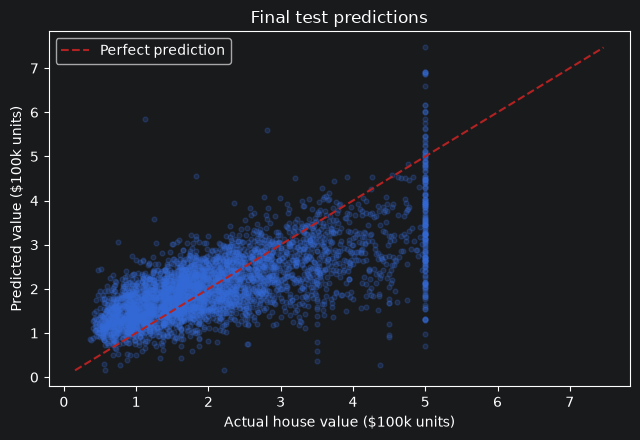

In [15]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(y_test, y_pred, s=12, alpha=0.22)
axis_min = min(y_test.min(), y_pred.min())
axis_max = max(y_test.max(), y_pred.max())
ax.plot(
    [axis_min, axis_max],
    [axis_min, axis_max],
    "--",
    color="firebrick",
    label="Perfect prediction",
)
ax.set(
    xlabel="Actual house value ($100k units)",
    ylabel="Predicted value ($100k units)",
    title="Final test predictions",
)
ax.legend()
plt.tight_layout()
plt.show()


## 5.8 Homework: Advanced Preprocessing and Model Comparison

**Goal:** Build a preprocessing pipeline for the modified California Housing dataset, train three regression models, and compare their performance on both the training and test sets. Pay particular attention to **missing values**, **feature engineering**, and **overfitting**.

Some feature groups require several transformations applied **in sequence**. Use `Pipeline` objects inside a `ColumnTransformer` to combine them. Your solution should use **all eight original numerical features**, as well as the derived categorical feature `HouseAge_cat`.

### 1. Prepare the Data

Work with the **modified dataset `X`** created in Section 5.2, together with its target `y`. In particular:

- Keep the categorical feature `HouseAge_cat`.
- Keep the deliberately introduced missing values in `Population` — **do not** replace them manually or switch back to `X_raw`.
- Check and report how many values are missing in each feature.
- Split the data into training and test sets (`test_size=0.20`, `random_state=67`). You may reuse the split from Section 6.3.

### 2. Design the Preprocessing

Create a `ColumnTransformer` containing **four branches**. For branches with multiple transformations, build an individual `Pipeline` and apply the transformations in the order shown.

#### A. Income, Population, and Household Characteristics

Apply the following transformations to `MedInc`, `Population`, `AveRooms`, and `AveBedrms`:

1. `SimpleImputer(strategy="median")` to handle missing values.
2. `StandardScaler()` to standardize the resulting features.
3. `PolynomialFeatures(degree=2, include_bias=False)` to generate quadratic and interaction features.

#### B. Geographic Coordinates

Apply the following transformations to `Latitude` and `Longitude`:

1. `MinMaxScaler(feature_range=(0, 1))`.
2. `PolynomialFeatures(degree=2, include_bias=False)`.

#### C. Other Numerical Features

Apply the following transformations to `HouseAge` and `AveOccup`:

1. `SimpleImputer(strategy="median")`.
2. `RobustScaler()`.

`RobustScaler` was introduced in Section 5.5. Unlike `StandardScaler`, it uses the median and interquartile range.

#### D. Categorical Features

Apply `OneHotEncoder(handle_unknown="ignore")` to `HouseAge_cat`. You may set `sparse_output=False` if you prefer a dense transformed matrix.

Combine branches A–D into **one `ColumnTransformer`**.

### 3. Inspect the Transformed Data

Fit the complete preprocessing object on the training features, then use it to transform both the training and test features.

- Report the dimensions of the original and transformed feature matrices.
- Check that no missing values remain in the transformed matrices.
- Determine how many features the preprocessing produces.

### 4. Train Three Regression Models

Train these regressors, all using **the same preprocessing configuration**:

1. `LinearRegression()`.
2. `Ridge()` (default parameters).
3. `DecisionTreeRegressor(random_state=67)` (otherwise default parameters).

For each regressor, create a complete `Pipeline` with the preprocessing object followed by the model. Fit each pipeline on the training set.

### 5. Evaluate and Compare the Models

For **each** model, predict on **both** the training and test sets and calculate:

- **Training RMSE**, using `y_train` and the training predictions.
- **Test RMSE**, using `y_test` and the test predictions.

Present your results in a clearly labelled table (preferably a pandas `DataFrame`), for example:

| Model | Train RMSE | Test RMSE |
|---|---:|---:|
| Linear Regression | ... | ... |
| Ridge | ... | ... |
| Decision Tree | ... | ... |

### 6. Interpret Your Results

Answer the following questions in a few sentences **based on your results**:

1. **Which model performs best on the training data? Does it also perform best on the test data?**
2. **Which model appears to overfit, and why?** Support your answer by comparing its training and test RMSE.
